In [ ]:
import pandas as pd
movies_df = pd.read_csv('movies_metadata_clean.csv')
ratings_df = pd.read_csv('ratings_clean.csv', sep=',')
merged_df = pd.merge(movies_df, ratings_df, left_on='id', right_on= 'movieId', how= 'inner')
print("Merging Successfully")
print(f"Dataset Shape; {merged_df.shape}")

Merging Successfully
Dataset Shape; (44989, 28)


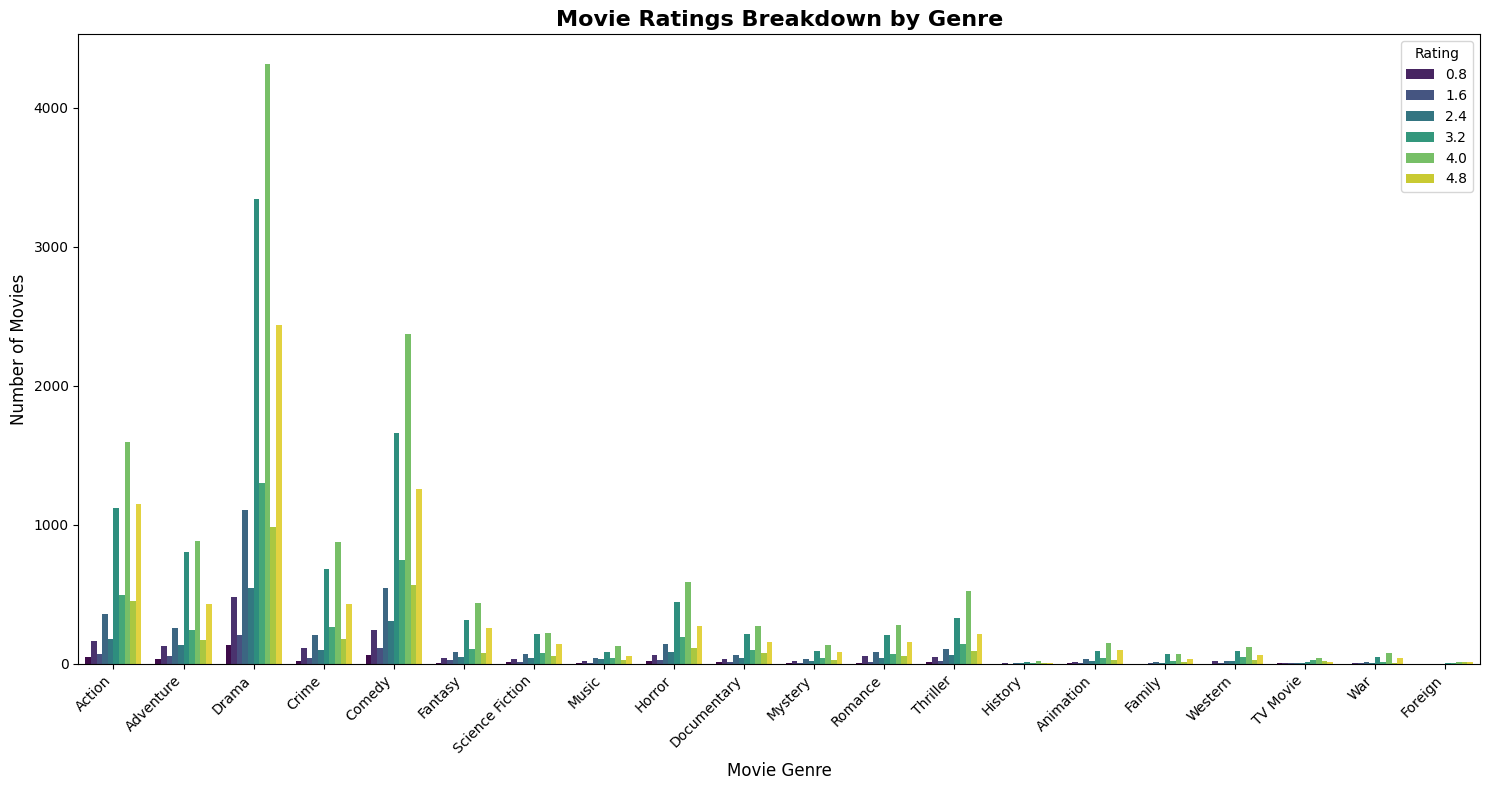

In [ ]:
import ast
import matplotlib.pyplot as plt
import seaborn as sns

def clean_genres(genre_str):
    try:
        genre_list = ast.literal_eval(genre_str)
        if isinstance(genre_list, list) and len(genre_list) > 0:
            return genre_list[0]['name']
        return None
    except:
        return None

merged_df['clean_genre'] = merged_df['genres'].apply(clean_genres)

plt.figure(figsize=(15, 8))

sns.countplot(
    data=merged_df.dropna(subset=['clean_genre']),
    x='clean_genre',
    hue='rating',
    palette='viridis'
)

plt.title('Movie Ratings Breakdown by Genre', fontsize=16, fontweight='bold')
plt.xlabel('Movie Genre', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)
plt.legend(title='Rating', loc='upper right')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import ast
credits_df = pd.read_csv('credits_cleaned (1).csv', sep=',')
def get_top_actor(cast_string):
  try:
    cast_list = ast.literal_eval(cast_string)
    if isinstance(cast_list, list) and len(cast_list) > 0:
      return cast_list[0]['name']
  except:
      return None
  return None
credits_df['clean_actor'] = credits_df['cast'].apply(get_top_actor)
final_df = pd.merge(merged_df, credits_df, on='id', how='inner')
top_actors_clean = final_df['clean_actor'].value_counts().head(5).reset_index()
top_actors_clean.columns = ['Actor Name', 'Number of Movies']

print("--- Top 5 Most Frequent Actors (Cleaned) ---")
print(top_actors_clean)




--- Top 5 Most Frequent Actors (Cleaned) ---
              Actor Name  Number of Movies
0     Sylvester Stallone               454
1  Arnold Schwarzenegger               412
2             Mel Gibson               404
3             Matt Damon               396
4              Tom Hanks               385


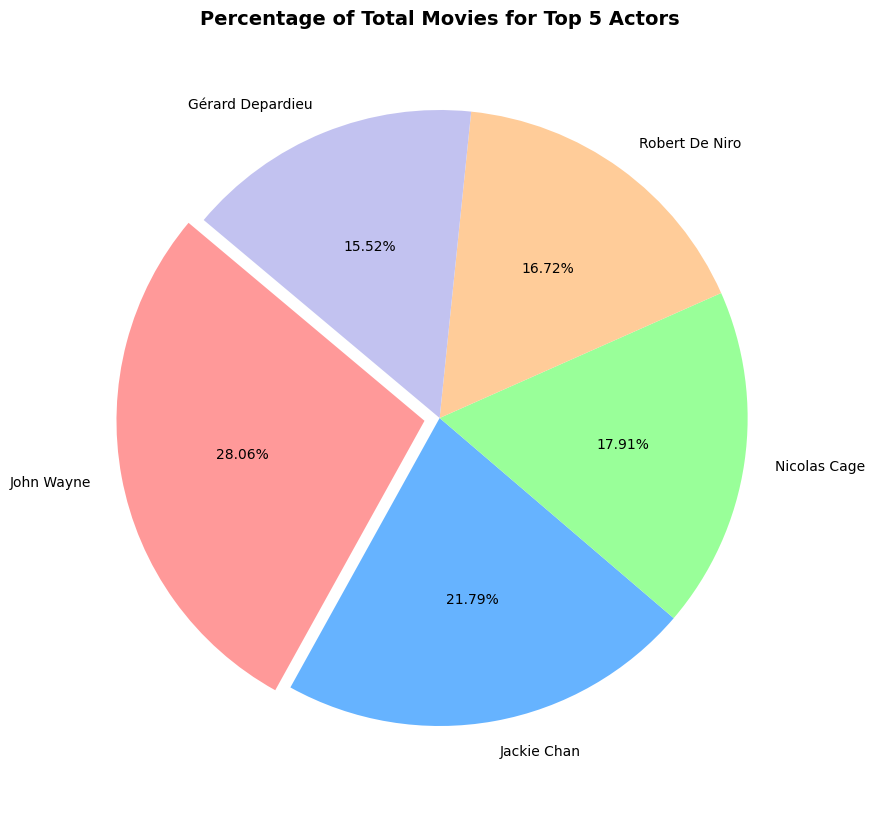

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

def get_main_actor(cast_string):
    try:
        cast_list = ast.literal_eval(cast_string)
        if isinstance(cast_list, list) and len(cast_list) > 0:
            return cast_list[0]['name']
        return None
    except:
        return None

credits_df = pd.read_csv('credits_cleaned (1).csv', sep=',')
credits_df['main_actor'] = credits_df['cast'].apply(get_main_actor)

total_movies = len(credits_df)
actor_counts = credits_df['main_actor'].value_counts().head(5)

actor_percentages = (actor_counts / total_movies) * 100

plt.figure(figsize=(10, 10))
plt.clf()

plt.pie(
    actor_percentages,
    labels=actor_percentages.index,
    autopct='%1.2f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0'],
    explode=(0.05, 0, 0, 0, 0)
)

plt.title('Percentage of Total Movies for Top 5 Actors', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
import pandas as pd
import ast

credits_df = pd.read_csv('credits_cleaned (1).csv', sep=',')

def get_director(crew_string):
    try:
        crew_list = ast.literal_eval(crew_string)
        if isinstance(crew_list, list):
            for member in crew_list:
                if member['job'] == 'Director':
                    return member['name']
    except:
        return None
    return None

credits_df['director'] = credits_df['crew'].apply(get_director)

top_directors = credits_df['director'].value_counts().head(5).reset_index()
top_directors.columns = ['Director Name', 'Number of Movies']
top_directors.index = top_directors.index + 1
print("--- Top 5 Most Frequent Directors Table ---")
display(top_directors)

--- Top 5 Most Frequent Directors Table ---


,Director Name,Number of Movies
1,John Ford,66
2,Michael Curtiz,65
3,Werner Herzog,54
4,Alfred Hitchcock,53
5,Georges Méliès,51
